##Convolutional Neural Networks



# **1. Pengenalan**

Praktikum ini menjelaskan bagaimana klasifikasi gambar pada data CIFAR-10 dataset. Pada praktikum ini akan dibuat sebuah classifier gambar dengan model Sequential `tf.keras.Sequential` dan load data menggunakan `tf.keras.preprocessing.image.ImageDataGenerator`. Anda akan memperoleh pengalaman sebagai berikut:

* Membangun _data input pipelines_ menggunakan `tf.keras.preprocessing.image.ImageDataGenerator` class untuk bekerja secara efisien dengan data pada disk untuk digunakan dengan model.
* _Overfitting_ —Bagaimana mencegah terjadinya overfitting.
* _Data augmentation_ and _dropout_ —Teknik-teknik utama untuk melawan overfitting dalam tugas-tugas Computer Vision untuk diintegrasikan ke dalam alur data dan model klasifikasi gambar.

Pekerjaan lab ini mengikuti alur kerja pembelajaran mesin dasar:

1. Memeriksa dan memahami data
2. Membangun alur input/masukan
3. Membangun model
4. Melatih model
5. Menguji model
6. Memperbaiki model dan mengulangi prosesnya

# **2. Mounting Google Drive**

In [1]:
from google.colab import drive
from os.path import join, exists

# mounting dataset dari gdrive
drive.mount('/content/gdrive', force_remount=True)

# folder ini juga digunakan untuk menyimpan model yang sudah dilatih
root_path = 'gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/'

# opsional - tampilkan info lokasi dataset
print("Path root:", root_path)

Mounted at /content/gdrive
Path root: gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/


# **3. Download Dataset**
Kita menggunakan CIFAR-10 Dataset yang terdiri 10 kelas.

In [2]:
!pip install datasets

import numpy as np
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# Load dataset
dataset = load_dataset("uoft-cs/cifar10")

# Ambil data training
X_data = np.array(dataset['train']['img'])
y_data = np.array(dataset['train']['label'])

# Ambil data testing
X_test = np.array(dataset['test']['img'])
y_test = np.array(dataset['test']['label'])

# Kategori dataset
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Membagi data training 70:30
X_train, X_val, y_train, y_val = train_test_split(
    X_data, y_data, test_size=0.3, random_state=42
)

y_train = y_train.ravel()
y_val = y_val.ravel()
y_test = y_test.ravel()

# Informasi dataset
num_class = len(class_names)

print('Jumlah kelas:', num_class)
print('Label kelas:', class_names)
print('Dimensi data latih:', X_train.shape)
print('Dimensi data validasi:', X_val.shape)
print('Dimensi data uji:', X_test.shape)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Jumlah kelas: 10
Label kelas: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Dimensi data latih: (35000, 32, 32, 3)
Dimensi data validasi: (15000, 32, 32, 3)
Dimensi data uji: (10000, 32, 32, 3)


## Visualisasi data

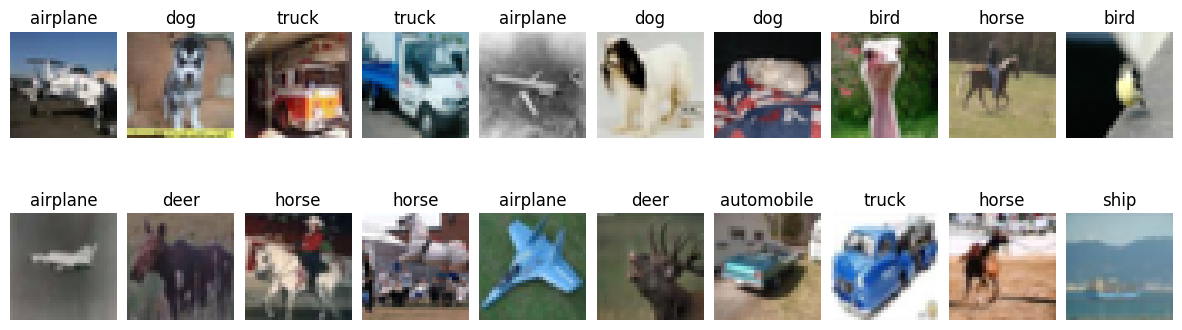

In [3]:
import matplotlib.pyplot as plt

%matplotlib inline

fig, ax = plt.subplots(2,10,figsize=(15,4.5))
fig.subplots_adjust(hspace=0.1, wspace=0.1)
for j in range(0,2):
    for i in range(0, 10):
        ax[j,i].imshow(X_train[i+j*10])
        ax[j,i].set_title(class_names[y_train[i+j*10]])
        ax[j,i].axis('off')
plt.show()

## Persiapkan dataset
Sebelumnya gambar-gambar harus di pre-process terlebih dahulu menjadi tensor yang mengandung angka-angka bilangan real (floating point) sebelum digunakan pada neural networks.

1. Baca gambar-gambar dari disk.
2. Decode isi dari gambar-gambar tersebut dan ubah menjadi grid format yang seusai dengan nilai RGB mereka.
3. Ubah menjadi floating point tensors
4. Rescale tensornya dari range 0 sampai 255 menjadi angka-angka pada range 0 dan 1, karena neural networks lebih prefer input dengan range nilai yang kecil. Penting bahwa training set dan test set harus diproses terlebih dahulu dengan cara yang sama.

Untungnya, semua langkah di atas dapat dilakukan dengan kelas `ImageDataGenerator` yang disediakan oleh `tf.keras`. Kelas tersebut dapat membaca gambar dari disk dan memprosesnya terlebih dahulu menjadi tensor yang tepat. Ia juga akan menyiapkan generator yang mengubah gambar-gambar ini menjadi kumpulan tensor saat melatih jaringan.

In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# input citra
input_size = (X_train[0].shape[0], X_train[0].shape[1], 3)

# ukuran batch 128
batch_size = 128

# inisialisasi generator data latih dengan augmentasi data
train_image_generator = ImageDataGenerator(rescale=1./255)

# inisialisasi generator data validasi
val_image_generator = ImageDataGenerator(rescale=1./255)

 # inisialisasi generator data uji
test_data_generator = ImageDataGenerator(rescale=1./255)

# buat generator data latih
train_data_gen = train_image_generator.flow(X_train, y_train,
                                            batch_size=batch_size,
                                            shuffle=True)
# buat generator data validasi
val_data_gen = val_image_generator.flow(X_val, y_val,
                                        batch_size=batch_size,
                                        shuffle=True)
# buat generator data uji
test_data_gen = test_data_generator.flow(X_test, y_test,
                                         batch_size=1,
                                         shuffle=True)

# **4. Membangun Model CNN**



Sebuah convolutional neural networks yang sederhana terdiri dari serangkaian layer, dan setiap layer mentransformasi satu volume aktivasi kepada aktivasi yang lainnya melalui fungsi yang "differentiable". Kita akan menggunakan tiga jenis layer untuk membangun Covolutional Neural Networks: **Convolutional Layer, Pooling Layer, dan Fully Connected Layer**. Kita akan menumpuk (stacking) layer-layer tersebut untuk membentuk arsitektur ConvNet yang full.

## **CNN Model**
 Sebuah arsitektur ConvNet sederhana untuk klasifikasi gambar pada dataset CIFAR-10 memiliki layer-layer sebagai berikut:
`[INPUT - CONV - RELU - POOL - FC]`


Lebih detail:

1. **INPUT** [32x32x3]
memegang nilai raw pixel dari gambar, dalam hal ini gambar berukuran lebar 32, tinggi 32, dan tiga channel warna yaitu R,G,B.
2. **CONV layer**
akan menghitung output dari neuron-neuron yang terkoneksi dengan input, komputasi yang dilakukan adalah dot product antara weights pada neuron dengan 'a small region' yang terhubung dengan input.

Contoh, hasilnya akan berukuran [32x32x12] jika kita menggunakan 12 filters.

<table>
  <tr><td  align="center">
    <img src="https://miro.medium.com/max/960/1*bx3kWA2cKm14OrNP1M-6gw.gif" width="80%"
         alt="Convolution Process">
  </td></tr>
  <tr><td align="center">
    <b>Figure 1:</b> Convolution Process.<br/>
  </td></tr>
</table>

3. **RELU layer**
akan mengaplikasikan elementwise activation function, misalnya fungsi max(0,x) untuk memberlakukan thresholding 0. Hal ini tidak membawa perubahan pada ukuran output ([32x32x12]).
4. **POOL layer**
akan melakukan 'a downsampling operation' (downsampling = mengurangi jumlah sample) sepanjang dimensi spasial (lebar, tinggi), menghasilkan perubahan ukuran pada output, misalnya [16x16x12].
5. **FC (i.e. fully-connected) layer**
akan menghitung skor setiap kelas pada target class, menghasilkan output dengan ukuran [1x1x10], dimana setiap angka dari 10 angka tersebut merupakan skor dari sebuah kelas, yang merupakan target class pada dataset CIFAR-10. Setiap neuron pada layer ini (sebagaimana namanya Fully Connected Layer) terhubung (connected) dengan setiap neuron di layer sebelumnya.

Dengan cara ini, ConvNets mengubah gambar input (gambar asal) layer by layer dari pixel aslinya menjadi skor setiap kelas pada target class. Perlu dicatat bahwa setiap layer memiliki parameter masing-masing. Secara khusus, lapisan CONV/FC melakukan transformasi dengan fungsi-fungsi yang tidak hanya aktivasi dari input, tetapi juga fungsi-fungsi dengan parameter (bobot/weight dan bias neuron).

Di sisi lain, layer RELU/POOL mengimplementasi fixed function. Parameter dalam lapisan CONV/FC akan dilatih dengan Gradient Descent sehingga skor kelas yang dihitung oleh ConvNet konsisten dengan label/target class dalam training set untuk setiap gambar.

## Contoh Model CNN

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D, Dense
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.layers import MaxPooling2D, Activation, Flatten
from tensorflow.keras.optimizers import Adam

## Buat model CNN dengan konfigurasi sebagai berikut:

**Convolutional block 1**
- conv layer dengan jumlah filter = 32, ukuran filter = 3x3, fungsi aktivasi relu
- conv layer dengan jumlah filter = 32, ukuran filter = 3x3, fungsi aktivasi relu
- max pooling layer dengan pooling size 2x2

**Convolutional block 2**
- conv layer dengan jumlah filter = 64, ukuran filter = 3x3, fungsi aktivasi relu
- conv layer dengan jumlah filter = 64, ukuran filter = 3x3, fungsi aktivasi relu
- max pooling layer dengan pooling size 2x2

**Convolutional block 3**
- conv layer dengan jumlah filter = 128, ukuran filter = 3x3, fungsi aktivasi relu
- conv layer dengan jumlah filter = 128, ukuran filter = 3x3, fungsi aktivasi relu
- max pooling layer dengan pooling size 2x2

**Flatten**

**Fully connected layer**
- Dense dengan jumlah neuron 128 dan fungsi aktivasi relu

**Output layer**
- Dense dengan jumlah neuron sejumlah kategori dari dataset CIFAR-10 dan fungsi aktivasi softmax

In [6]:
cnn_model1 = Sequential()

# the first convolutional block
cnn_model1.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_size))
cnn_model1.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
# max pooling
cnn_model1.add(MaxPooling2D(pool_size=(2, 2)))

# the second convolutional block
cnn_model1.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
cnn_model1.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
# max pooling
cnn_model1.add(MaxPooling2D(pool_size=(2, 2)))

# the third convolutional block
cnn_model1.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
cnn_model1.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
# max pooling
cnn_model1.add(MaxPooling2D(pool_size=(2, 2)))

# flatten
cnn_model1.add(Flatten())

# fully connected layer
cnn_model1.add(Dense(128, activation='relu'))

# last layer untuk klasifikasi gambar
cnn_model1.add(Dense(num_class, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Compile the model

Sebelum model siap untuk ditraining, Beberapa setting perlu dilakukan. Setting ini dilakukan pada fungsi model.compile:

*Loss function* — Fungsi untuk mengukur seberapa akurat model selama training. Kita ingin meminimalkan fungsi ini untuk "mengarahkan" model ke arah yang benar, yaitu memiliki performa yang maksimal.

*Optimizer* — Fungsi bagaimana model diupdate berdasarkan data yang dilihat dan berdasarkan loss function.

*Metrics* — Metrics digunakan untuk memonitor step-step training dan testing. Salah satu contohnya adalah 'accuracy', yaitu jumlah gambar yang dapat diprediksi dengan benar.

Pada praktikum ini kita akan menggunakan *ADAM* optimizer dan *binary cross entropy* untuk loss function. Untuk melihat akurasi training dan validasi pada setiap epoch, gunakan argumen `metrics`.

In [7]:
# Path to save the best model.
checkpoint_filepath = join(root_path, 'cnn_model1.h5')

model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath, save_weights_only=False,
    monitor='val_loss', verbose=1, mode='auto', save_best_only=True)

opt = keras.optimizers.Adam(learning_rate=0.0001) # '1e-4' bisa diisi dengan ini

cnn_model1.compile(optimizer=opt,
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

### Model summary

Melihat summary dari setiap layer pada neural networks:

In [8]:
cnn_model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 550,570 (2.10 MB)

 Trainable params: 550,570 (2.10 MB)

 Non-trainable params: 0 (0.00 B)

# **5. Pelatihan Model CNN**
Training the neural network model requires the following steps:

1. Masukkan training data ke model. Pada contoh ini, training data terdapat pada  array ```train_images``` dan ```train_labels``` .

2. The model belajar untuk mengasosiasikan gambar dengan label/target class.

3. Dataset untuk pengujian (testing) terdapat pada array ```test_images``` .

4. Verifikasi apakah hasil prediksi sesuai dangan label pada ```test_labels``` array.

Untuk memulai training, panggil  ```model.fit```

In [9]:
epochs = 20

history = cnn_model1.fit(
    train_data_gen,
    epochs=epochs,
    validation_data=val_data_gen,
    callbacks=[model_checkpoint_callback],
    verbose=1)

Epoch 1/20
265/274 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.2019 - loss: 2.1170
Epoch 1: val_loss improved from None to 1.63337, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 1: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 33s 67ms/step - accuracy: 0.2931 - loss: 1.9284 - val_accuracy: 0.4130 - val_loss: 1.6334
Epoch 2/20
264/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4146 - loss: 1.6227
Epoch 2: val_loss improved from 1.63337 to 1.47503, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 2: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4303 - loss: 1.5715 - val_accuracy: 0.4615 - val_loss: 1.4750
Epoch 3/20
265/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4698 - loss: 1.4742
Epoch 3: val_loss improved from 1.47503 to 1.37490, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 3: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4806 - loss: 1.4442 - val_accuracy: 0.5005 - val_loss: 1.3749
Epoch 4/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5092 - loss: 1.3694
Epoch 4: val_loss improved from 1.37490 to 1.31178, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 4: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5145 - loss: 1.3559 - val_accuracy: 0.5294 - val_loss: 1.3118
Epoch 5/20
272/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5398 - loss: 1.2915
Epoch 5: val_loss improved from 1.31178 to 1.23384, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 5: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5421 - loss: 1.2888 - val_accuracy: 0.5599 - val_loss: 1.2338
Epoch 6/20
271/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5648 - loss: 1.2420
Epoch 6: val_loss improved from 1.23384 to 1.22719, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5


... (3 outputs left out)


Epoch 9: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6239 - loss: 1.0785 - val_accuracy: 0.6183 - val_loss: 1.0917
Epoch 10/20
270/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6303 - loss: 1.0459
Epoch 10: val_loss improved from 1.09174 to 1.07152, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 10: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6335 - loss: 1.0469 - val_accuracy: 0.6215 - val_loss: 1.0715
Epoch 11/20
273/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6472 - loss: 1.0058
Epoch 11: val_loss improved from 1.07152 to 1.02805, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5



Epoch 11: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model1.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6492 - loss: 1.0022 - val_accuracy: 0.6380 - val_loss: 1.0281
Epoch 12/20
266/274 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6550 - loss: 0.9799

KeyboardInterrupt: 

### Visualisasi Hasil Training
Visualisasi Hasil Training Convolutional Neural Networks.

In [ ]:
# ambil statistik pelatihan
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']

epochs_range = range(epochs)

# plot hasil akurasi pelatihan
plt.figure(figsize=(18, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('accuracy')
plt.xlabel('epochs')
plt.title('Training Accuracy')

# plot hasil loss pelatihan
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.title('Training Loss')
plt.show()

Seperti yang dapat kita lihat pada plot, akurasi pada data training dan data validasi sangat berbeda jauh dan model hanya mencapai akurasi 70% pada dataset validasi.

Gap yang besar pada akurasi training dan validasi menunjukkan adanya OVERFITTING. Overfitting terjadi pada sebuah model machine learning jika akurasinya dalam memprediksi data-data baru lebih buruk daripada akurasinya pada data training.

Model yang mengalami overfitting lebih "mengingat" data training dan memiliki akurasi yang rendah pada data validasi.

Mari kita cek apa yang salah dan mencoba untuk menaikkan performa model.

# **6. Managing Overfitting**
Pada plot di atas, akurasi training meningkat secara linear terhadap waktu, sedangkan akurasi validasi masih berkisar pada nilai 70% selama proses training. Perbedaan akurasi ini dapat mengindikasikan terjadinya *overfitting*.

Jika terdapat hanya sedikit data pada data training, model terkadang belajar dari anomali atau detail yang tidak diinginkan dari data training—sehingga malah berdampak negatif pada kinerja model pada data baru. Fenomena ini dikenal sebagai overfitting. Ini berarti bahwa model akan kesulitan melakukan "generalisasi" pada dataset yang baru.

Ada beberapa cara untuk menangani overfitting pada proses training. Pada praktikum ini kita akan gunakan *data augmentation* dan menambahkan *dropout* pada model supaya dapat mengurangi overfitting.

## Augmentasi Data
Overfitting biasanya dapat terjadi jika data training hanya memiliki sedikit data. Salah satu cara untuk menangani overfitting adalah melakukan "augmentasi" (penambahan) dataset sehingga kita memiliki data training yang cukup. Augmentasi data dilakukan dengan menambah lebih banyak data training dari sampel training yang sudah ada dengan melakukan augmentasi sampel  menggunakan transformasi secara random/acak yang menghasilkan gambar yang tampak meyakinkan. Tujuannya adalah model tidak akan pernah melihat gambar yang sama persis dua kali selama training. Hal ini membantu memaparkan model ke lebih banyak aspek data sehingga menggeneralisasi dengan lebih baik.

Implementasi augmentasi data menggunakan `tf.keras` using the `ImageDataGenerator` class. Gunakan transformasi yang berbeda-beda pada dataset dan transformasi tersebut akan diaplikasikan selama training.

### Augmentasi dan Visualisasi data

Kita dapat menggunakan teknik "data augmentation" untuk menambah jumlah data pada training dataset, dengan membangkitkan data baru dari data yang sudah ada dengan mengaplikasikan transformasi random(sebagai contoh, rotasi).

Hal ini terutama efektif jika bekerja dengan gambar. Sebagai contoh, data training yang kita miliki hanya mengandung gambar-gambar kucing  that menghadap kanan. Maka, jika dataset validasi kita mengandung gambar kucing yang posisinya terbalik (kepala di bawah, badan di atas) model kita akan kesulitan dalam melakukan klasifikasi dengan tepat.

Augmentasi data dibangun dengan ImageDataGenerator. Anda dapat menggunakan berbagai jenis transformasi, dan akan diaplikasikan selama proses training.

Kita akan mulai dengan mengaplikasikan random horizontal flip pada dataset dan lihat bagaimana setiap gambar akan tampak setelah transformasi tersebut.

### Apply horizontal flip

Gunakan `horizontal_flip` sebagai argumen pada `ImageDataGenerator` class dan set `True` untuk mengaplikasikan augmentasi tersebut.

### Randomly rotate the image

Kita akan coba transformasi yang lain yaitu rotasi dan aplikasikan rotasi 20 derajat secara random pada data training.

### Apply zoom augmentation

Aplikasikan zoom augmentation pada dataset sehingga gambar akan di-zoom sampai 20% secara random.



In [10]:
# buat prosedur augmentasi pada data
new_train_image_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    # width_shift_range=.1,
    # height_shift_range=.1,
    horizontal_flip=True,
    zoom_range=0.2)

# terapkan augmentasi pada data latih
new_train_data_gen = new_train_image_generator.flow(X_train, y_train,
                                            batch_size=batch_size,
                                            shuffle=True)

Tampilkan hasil augmentasi data

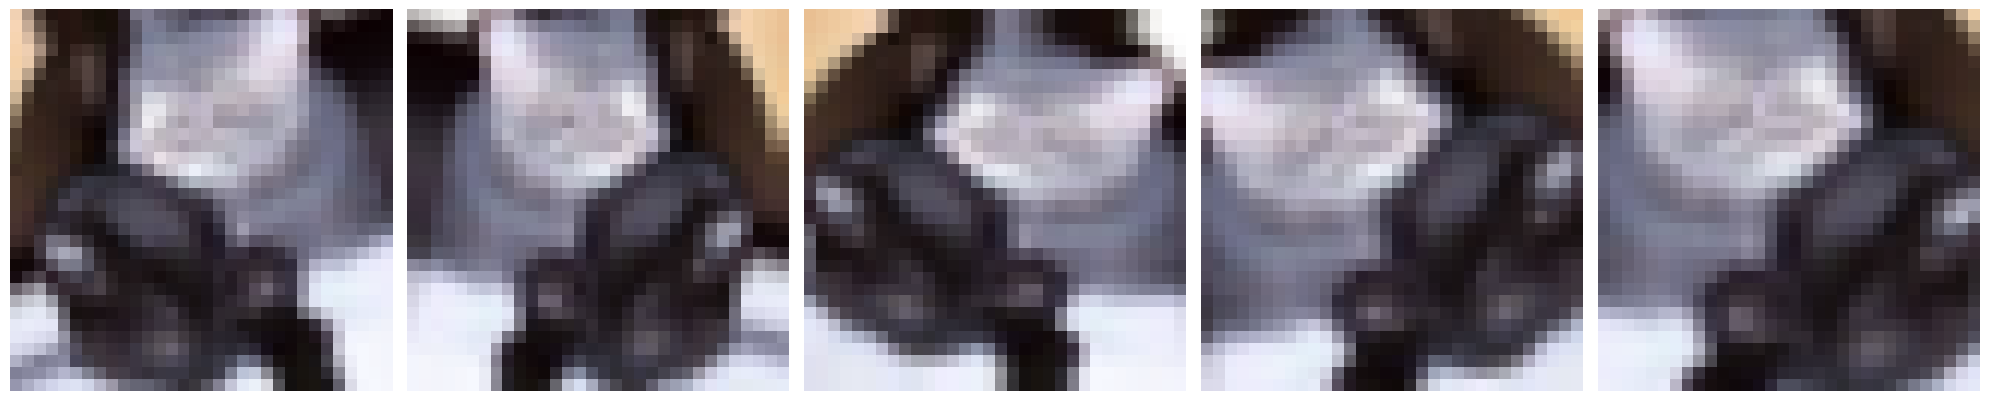

In [11]:
augmented_images = [new_train_data_gen[0][0][0] for i in range(5)]

fig, axes = plt.subplots(1, 5, figsize=(20,20))
axes = axes.flatten()
for img, ax in zip(augmented_images, axes):
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Dropout
Teknik yang lain untuk mengurangi overfitting adalah menggunakan *dropout* pada network. Dropout adalah sebuah bentuk *regularization* yang memaksa network untuk mengambil weights/bobot yang bernilai kecil, yang membuat distribusi nilai bobot lebih teratur dan network dapat mengurangi overfitting pada data training yang sedikit.

Ketika mengaplikasikan Dropout pada sebuah layer,  ini berarti secara random akan menge-set sejumlah unit pada layer tersebut menjadi NOL selama proses training. Dropout mengambil angka pecahan sebagai nilai inputnya, dalam bentuk seperti 0,1, 0,2, 0,4, dst. Hal ini berarti melakukan dropout pada 10%, 20% atau 40% dari units pada layer tersebut secara random .

Ketika mengaplikasikan dropout 0.1 pada suatu layer tertentu, ini secara random akan mematikan 10% unit output pada setiap epoch.

Kita akan mencoba menerapkan dropout pada network yang kita bangun, terutama pada layer Konvolusi (convolution) dan Fully Connected Layer.

# **7. Membuat CNN dengan Dropouts dan Batch Normalization**
Menerapkan dropout dengan porsi 25% berarti bahwa kita akan meng-set 25% dari neuron dengan zero (0) pada setiap epoch pelatihan. Hal ini akan membantu mengurangi overfitting pada training/pelatihan.

Terapkan dropout 25% pada model cnn berikut.

In [ ]:
cnn_model2 = Sequential()

# the first convolutional block
cnn_model2.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_size))
cnn_model2.add(BatchNormalization())
cnn_model2.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
cnn_model2.add(BatchNormalization())
# max pooling
cnn_model2.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model2.add(Dropout(0.25))

# the second convolutional block
cnn_model2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
cnn_model2.add(BatchNormalization())
cnn_model2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
cnn_model2.add(BatchNormalization())
# max pooling
cnn_model2.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model2.add(Dropout(0.25))

# the third convolutional block
cnn_model2.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
cnn_model2.add(BatchNormalization())
cnn_model2.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
cnn_model2.add(BatchNormalization())
# max pooling
cnn_model2.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model2.add(Dropout(0.25))

# flatten
cnn_model2.add(Flatten())

# fully connected layer
cnn_model2.add(Dense(128, activation='relu'))
cnn_model2.add(Dropout(0.25))

# last layer
cnn_model2.add(Dense(num_class, activation='softmax'))

### Compile the model
Setelah menambahkan dropout pada network, kita akan compile ulang modelnya.

In [ ]:
# Path to save the best model.
checkpoint_filepath = join(root_path, 'cnn_model2.h5')

model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath, save_weights_only=False,
    monitor='val_loss', verbose=1, mode='auto', save_best_only=True)

opt = keras.optimizers.Adam(learning_rate=0.0001)

cnn_model2.compile(optimizer=opt,
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
cnn_model2.summary()

### Train the model
Setelah melakukan data augmentation pada data training, kita tambahkan parameter dropout pada network, lalu training kembali network nya:

In [ ]:
epochs = 20

history2 = cnn_model2.fit(
    new_train_data_gen, # training data yang baru setelah augmentasi -> new_train_data_gen
    epochs=epochs,
    validation_data=val_data_gen,
    callbacks=[model_checkpoint_callback],
    verbose=1)

### Visualize training results
Visualisasi hasil training Convolutional Neural Networks

In [ ]:
# ambil statistik pelatihan
acc = history2.history['accuracy']
val_acc = history2.history['val_accuracy']
loss=history2.history['loss']
val_loss=history2.history['val_loss']

epochs_range = range(epochs)

# plot hasil akurasi pelatihan
plt.figure(figsize=(18, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('accuracy')
plt.xlabel('epochs')
plt.title('Training Accuracy')

# plot hasil loss pelatihan
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.title('Training Loss')
plt.show()

Seperti yang anda lihat pada grafik pelatihan diatas bahwa sudah tidak terjadi overfitting dan validation loss masih turun terus dan validation akurasi masih naik terus sehingga anda dapat menambah jumlah epoch pelatihannya sampai tidak ada perubahan yang signifikan.

# **8. Model Evaluation**

In [17]:
from tensorflow.keras.models import load_model

# load hasil pelatihan untuk di uji
trained_model = load_model(checkpoint_filepath)

# pengujian dengan data uji
trained_model.evaluate(test_data_gen, verbose=1)

10000/10000 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.6308 - loss: 1.0379


[1.0378841161727905, 0.6308000087738037]

# **9. Post Test**
1. Copy kode di **bagian 7: Creating CNN with Dropouts and Batch Normalization** yang sudah anda perbaiki
2. Buat teks baru dibawah kode tersebut dan diberi nama **Model CNN: Post Test**
3. Buat kode baru dibawah teks tersebut lalu paste kode dari Model CNN di soal nomor 1.
4. Ubah nama variabel model tersebut dari **cnn_model2 menjadi cnn_model_posttest**.
5. Ubah nama file untuk menyimpan model dari **cnn_model2.h5 menjadi cnn_model_posttest.h5**.
6. **Modifikasi model CNN tersebut dan tambah jumlah epoch**  dan **porsi dropout** sehingga anda bisa mendapatkan akurasi pelatihan, validasi dan pengujian yang lebih tinggi dari model CNN sebelumnya.
7. Jalankan kode untuk pelatihan sampai evaluasi dengan model Post Test yang anda buat.
8. Cermati hasil akurasi pengujiannya!

**Semakin tinggi akurasi yang anda dapatkan dibandingkan dengan hasil akurasi Model CNN sebelumnya maka semakin baik nilai post test anda**

## Model CNN: Post Test

In [12]:
# 1. Inisialisasi Model Baru dengan Modifikasi Dropout
cnn_model_posttest = Sequential()

# Convolutional block 1
cnn_model_posttest.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_size))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model_posttest.add(Dropout(0.3)) # Meningkatkan dropout sedikit untuk generalisasi lebih baik

# Convolutional block 2
cnn_model_posttest.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model_posttest.add(Dropout(0.3))

# Convolutional block 3
cnn_model_posttest.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(MaxPooling2D(pool_size=(2, 2)))
cnn_model_posttest.add(Dropout(0.3)) # Menambah dropout pada lapisan dalam

# Flatten
cnn_model_posttest.add(Flatten())

# Fully connected layer
cnn_model_posttest.add(Dense(128, activation='relu'))
cnn_model_posttest.add(BatchNormalization())
cnn_model_posttest.add(Dropout(0.3))

# Output layer
cnn_model_posttest.add(Dense(num_class, activation='softmax'))

In [13]:
# 2. Compile Model Post Test
checkpoint_filepath_posttest = join(root_path, 'cnn_model_posttest.h5')

model_checkpoint_callback_posttest = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath_posttest, save_weights_only=False,
    monitor='val_loss', verbose=1, mode='auto', save_best_only=True)

opt = keras.optimizers.Adam(learning_rate=0.0005)

cnn_model_posttest.compile(optimizer=opt,
                           loss='sparse_categorical_crossentropy',
                           metrics=['accuracy'])
cnn_model_posttest.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [14]:
# 3. Pelatihan Model dengan Peningkatan Epoch ke 50
epochs_posttest = 50

history_posttest = cnn_model_posttest.fit(
    new_train_data_gen,
    epochs=epochs_posttest,
    validation_data=val_data_gen,
    callbacks=[model_checkpoint_callback_posttest],
    verbose=1)

Epoch 1/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.2957 - loss: 2.1993
Epoch 1: val_loss improved from None to 3.36211, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 1: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 47s 114ms/step - accuracy: 0.3606 - loss: 1.8964 - val_accuracy: 0.1192 - val_loss: 3.3621
Epoch 2/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.4514 - loss: 1.5499
Epoch 2: val_loss improved from 3.36211 to 1.44599, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 2: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 19s 69ms/step - accuracy: 0.4639 - loss: 1.5007 - val_accuracy: 0.4809 - val_loss: 1.4460
Epoch 3/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5121 - loss: 1.3630
Epoch 3: val_loss improved from 1.44599 to 1.34813, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 3: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.5245 - loss: 1.3330 - val_accuracy: 0.5430 - val_loss: 1.3481
Epoch 4/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5667 - loss: 1.2179
Epoch 4: val_loss improved from 1.34813 to 1.16786, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 4: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.5732 - loss: 1.1995 - val_accuracy: 0.6026 - val_loss: 1.1679
Epoch 5/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5981 - loss: 1.1344
Epoch 5: val_loss improved from 1.16786 to 1.02239, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 5: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.6053 - loss: 1.1136 - val_accuracy: 0.6523 - val_loss: 1.0224
Epoch 6/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6237 - loss: 1.0534
Epoch 6: val_loss improved from 1.02239 to 1.00737, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5


... (10 outputs left out)


Epoch 30: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.8023 - loss: 0.5634 - val_accuracy: 0.8245 - val_loss: 0.5139
Epoch 31/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8109 - loss: 0.5433
Epoch 31: val_loss did not improve from 0.51386
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - accuracy: 0.8085 - loss: 0.5513 - val_accuracy: 0.7988 - val_loss: 0.6325
Epoch 32/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8123 - loss: 0.5430
Epoch 32: val_loss did not improve from 0.51386
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - accuracy: 0.8111 - loss: 0.5461 - val_accuracy: 0.8195 - val_loss: 0.5426
Epoch 33/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8146 - loss: 0.5308
Epoch 33: val_loss did not improve from 0.51386
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 61ms/step - accuracy: 0.8146 - loss: 0.5346 - val_accuracy: 0.8165 - val_loss: 0.


Epoch 36: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.8183 - loss: 0.5188 - val_accuracy: 0.8290 - val_loss: 0.5118
Epoch 37/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8216 - loss: 0.5092
Epoch 37: val_loss did not improve from 0.51181
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - accuracy: 0.8207 - loss: 0.5120 - val_accuracy: 0.8110 - val_loss: 0.5770
Epoch 38/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8270 - loss: 0.4951
Epoch 38: val_loss did not improve from 0.51181
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step - accuracy: 0.8259 - loss: 0.5044 - val_accuracy: 0.7969 - val_loss: 0.6374
Epoch 39/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8280 - loss: 0.4958
Epoch 39: val_loss did not improve from 0.51181
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 61ms/step - accuracy: 0.8247 - loss: 0.5016 - val_accuracy: 0.8232 - val_loss: 0.


Epoch 41: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.8260 - loss: 0.4942 - val_accuracy: 0.8337 - val_loss: 0.5080
Epoch 42/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8318 - loss: 0.4806
Epoch 42: val_loss did not improve from 0.50803
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 64ms/step - accuracy: 0.8301 - loss: 0.4869 - val_accuracy: 0.7848 - val_loss: 0.6786
Epoch 43/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8310 - loss: 0.4814
Epoch 43: val_loss improved from 0.50803 to 0.46853, saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5



Epoch 43: finished saving model to gdrive/My Drive/Colab Notebooks/Deep Learning Labs/Prak04_Data/cnn_model_posttest.h5
274/274 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.8295 - loss: 0.4848 - val_accuracy: 0.8437 - val_loss: 0.4685
Epoch 44/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.8402 - loss: 0.4603
Epoch 44: val_loss did not improve from 0.46853
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 63ms/step - accuracy: 0.8349 - loss: 0.4739 - val_accuracy: 0.8437 - val_loss: 0.4710
Epoch 45/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8298 - loss: 0.4807
Epoch 45: val_loss did not improve from 0.46853
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 61ms/step - accuracy: 0.8316 - loss: 0.4817 - val_accuracy: 0.8350 - val_loss: 0.4974
Epoch 46/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8373 - loss: 0.4696
Epoch 46: val_loss did not improve from 0.46853
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 60ms/step - accuracy: 0.8365 - loss: 0.4724 - val_accuracy: 0.8387 - val_loss: 0.

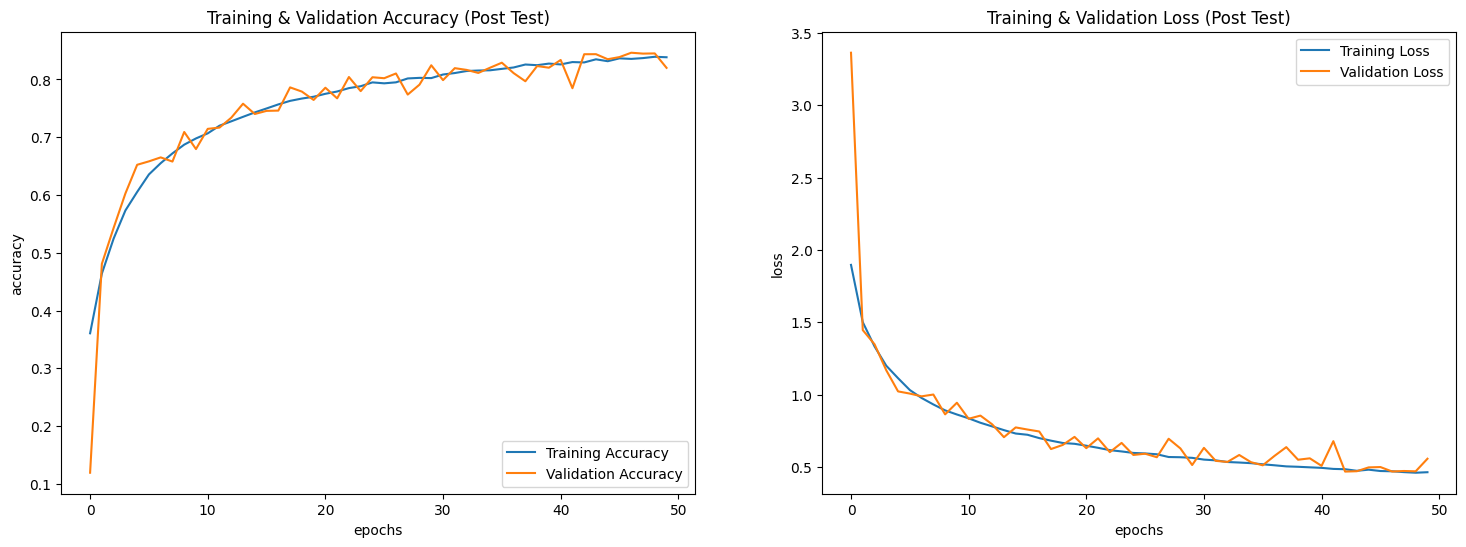

In [15]:
# 4. Visualisasi Hasil Training Post Test
acc_pt = history_posttest.history['accuracy']
val_acc_pt = history_posttest.history['val_accuracy']
loss_pt = history_posttest.history['loss']
val_loss_pt = history_posttest.history['val_loss']

epochs_range_pt = range(epochs_posttest)

plt.figure(figsize=(18, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range_pt, acc_pt, label='Training Accuracy')
plt.plot(epochs_range_pt, val_acc_pt, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('accuracy')
plt.xlabel('epochs')
plt.title('Training & Validation Accuracy (Post Test)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range_pt, loss_pt, label='Training Loss')
plt.plot(epochs_range_pt, val_loss_pt, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.title('Training & Validation Loss (Post Test)')
plt.show()

In [18]:
# 5. Evaluasi Akhir Menggunakan Model Terbaik Terpilih
trained_model_posttest = load_model(checkpoint_filepath_posttest)
trained_model_posttest.evaluate(test_data_gen, verbose=1)

10000/10000 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.8349 - loss: 0.4970


[0.4969750940799713, 0.8349000215530396]

### Kesimpulan Post Test

Berdasarkan hasil eksperimen pada model CNN Post Test, modifikasi yang dilakukan berhasil meningkatkan performa klasifikasi secara signifikan:

1. **Akurasi Pengujian (Test Accuracy):** Meningkat dari **63.08%** pada model cnn_model2 menjadi **83.49%** pada model cnn_model_posttest.
2. **Pencegahan Overfitting:** Peningkatan porsi dropout menjadi 30% (0.30) dan penambahan Batch Normalization terbukti efektif menjaga kestabilan nilai loss dan akurasi antara data latih dan validasi hingga epoch ke-50.
3. **Pembelajaran Model:** Dengan menambah jumlah epoch dan menyesuaikan learning rate, model mendapatkan kesempatan lebih banyak untuk menggeneralisasi fitur gambar pada dataset CIFAR-10 dengan lebih optimal.